In [92]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("Week 2 Data Cleaning Project Started!")

Pandas version: 2.2.3
NumPy version: 2.1.3
Week 2 Data Cleaning Project Started!


In [93]:
import pandas as pd
import numpy as np

# Load the uploaded dataset
df = pd.read_csv("/content/student_data (2).csv")

# Display the first five rows
print("First 5 Rows:")
display(df.head())

# Check dataset dimensions
print("\nDataset Shape (Rows, Columns):")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Generate summary statistics
print("\nSummary Statistics:")
display(df.describe(include="all").T)

First 5 Rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



Dataset Shape (Rows, Columns):
(395, 33)

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  rea

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [94]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize missing values in each column
missing = df.isnull().sum()
missing = missing[missing > 0]

if len(missing) > 0:
    missing.plot(kind="bar", figsize=(10, 5))
    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset.")

No missing values found in the dataset.


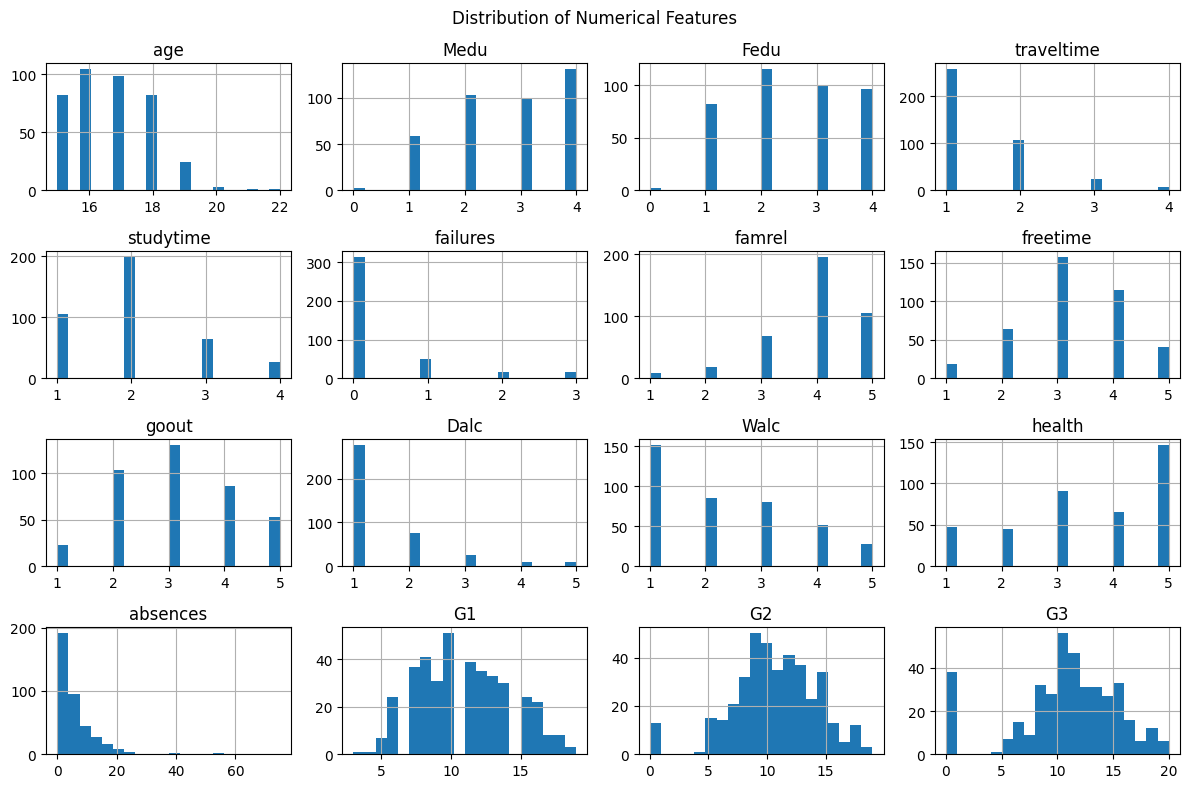

In [95]:
# Select numerical columns
numeric_columns = df.select_dtypes(include="number").columns

# Plot histograms
if len(numeric_columns) > 0:
    df[numeric_columns].hist(figsize=(12, 8), bins=20)
    plt.suptitle("Distribution of Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns found.")

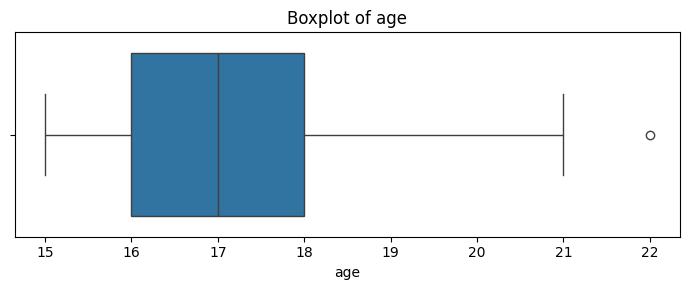

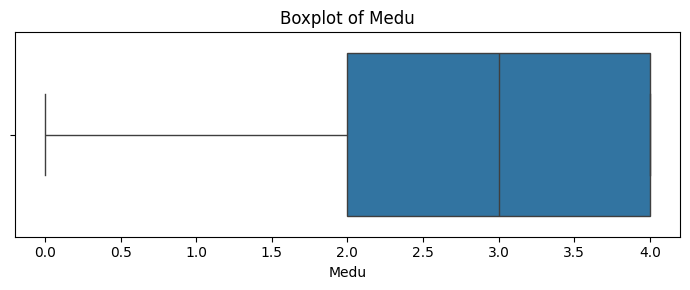

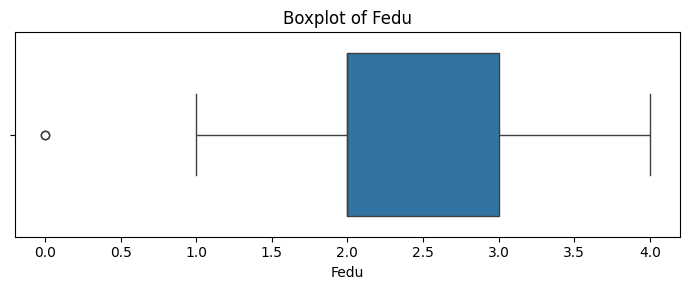

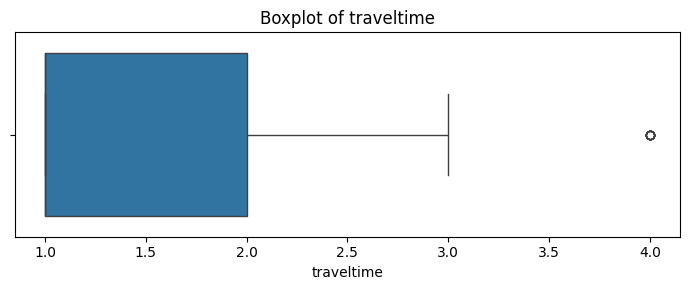

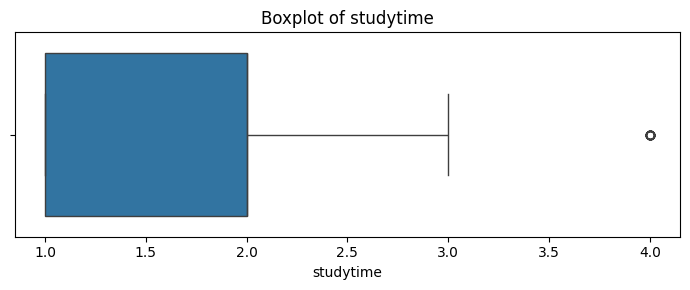

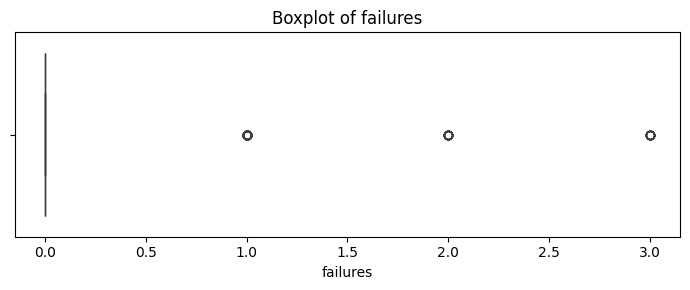

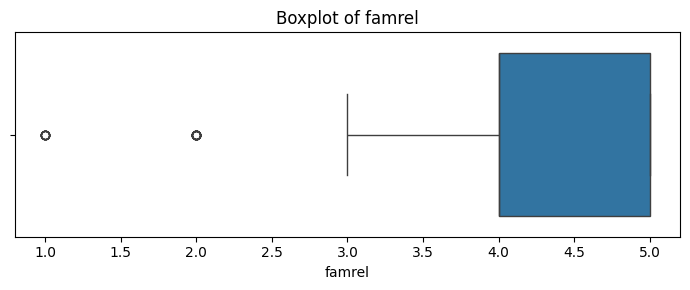

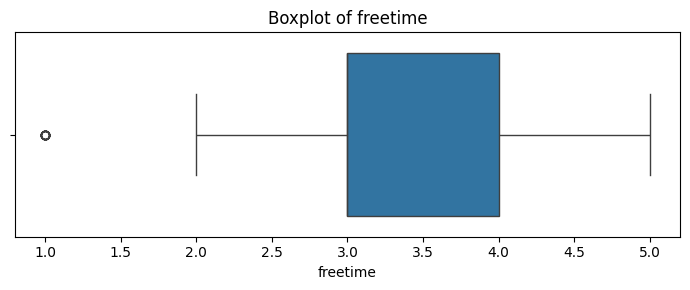

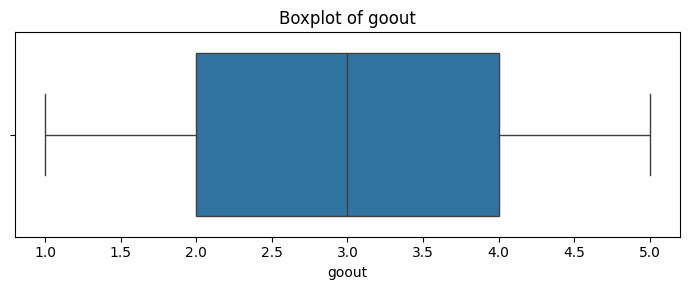

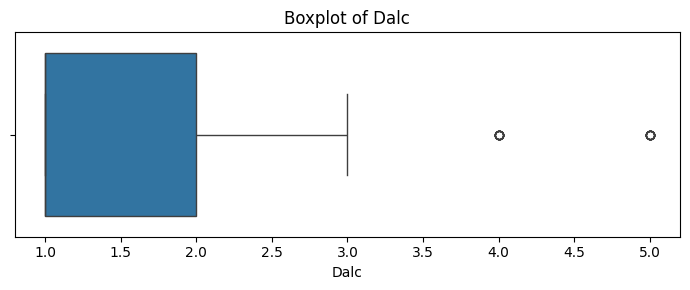

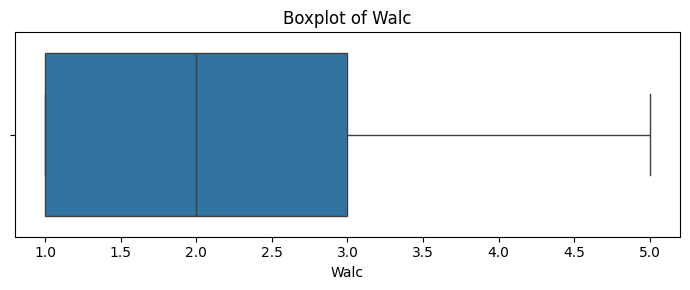

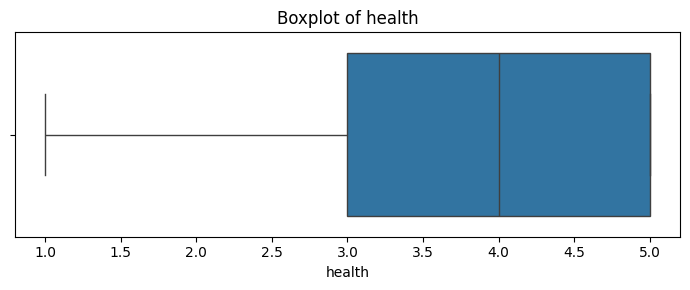

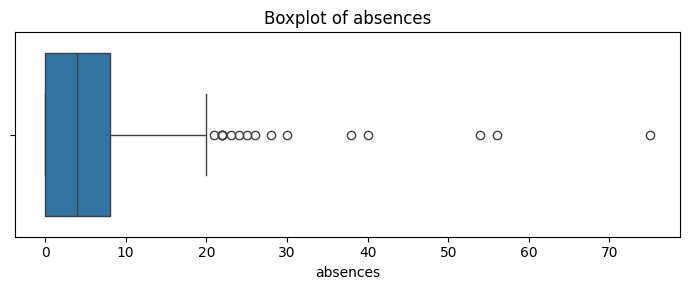

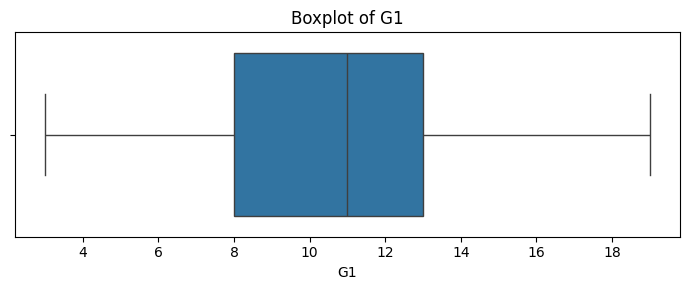

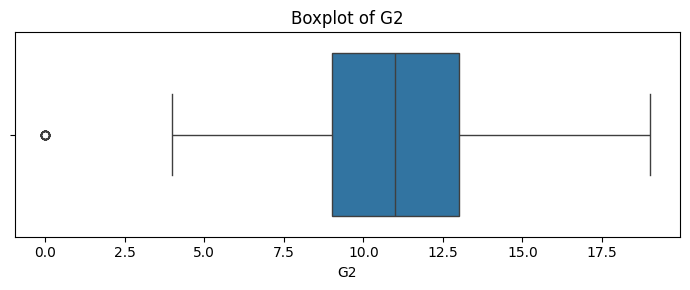

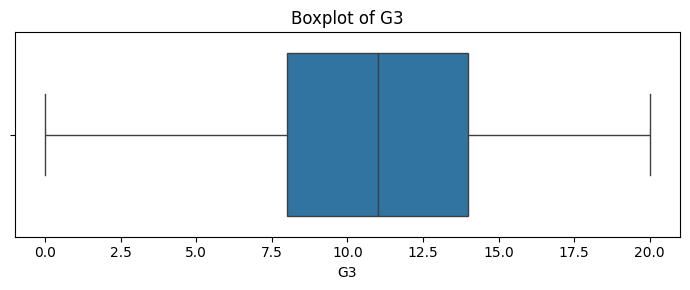

In [96]:
# Boxplots for numerical columns
if len(numeric_columns) > 0:
    for col in numeric_columns:
        plt.figure(figsize=(7, 3))
        sns.boxplot(x=df[col])
        plt.title(f"Boxplot of {col}")
        plt.tight_layout()
        plt.show()
else:
    print("No numerical columns available for boxplots.")

In [97]:
# Count duplicate records
duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

# Display duplicates if any exist
if duplicate_count > 0:
    print("\nDuplicate records found:")
    display(df[df.duplicated(keep=False)])
else:
    print("No duplicate records found.")

# Remove duplicate records if present
df_clean = df.drop_duplicates().copy()

print("\nOriginal dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

Total duplicate records: 0
No duplicate records found.

Original dataset shape: (395, 33)
Cleaned dataset shape: (395, 33)


In [98]:
# Create a separate working copy
df_clean = df_clean.copy()

# Check column names, data types and values
print("Column names:")
print(df_clean.columns.tolist())

print("\nData types:")
print(df_clean.dtypes)

print("\nUnique values in categorical columns:")
categorical_cols = df_clean.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False).head(15))

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             

In [99]:
# Detect potential outliers using the IQR method
numeric_cols = df_clean.select_dtypes(
    include="number"
).columns

for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} potential outliers")

age: 1 potential outliers
Medu: 0 potential outliers
Fedu: 2 potential outliers
traveltime: 8 potential outliers
studytime: 27 potential outliers
failures: 83 potential outliers
famrel: 26 potential outliers
freetime: 19 potential outliers
goout: 0 potential outliers
Dalc: 18 potential outliers
Walc: 0 potential outliers
health: 0 potential outliers
absences: 15 potential outliers
G1: 0 potential outliers
G2: 13 potential outliers
G3: 0 potential outliers


In [100]:
# Create a separate dataset for transformations
df_transformed = df_clean.copy()

# Identify categorical columns
categorical_cols = df_transformed.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:", categorical_cols)

# Apply one-hot encoding
df_transformed = pd.get_dummies(
    df_transformed,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)

print("\nDataset after encoding:")
display(df_transformed.head())

print("Shape after encoding:", df_transformed.shape)

Categorical columns: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Dataset after encoding:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,0,1,0,1,1,0,1,0
1,17,1,1,1,2,0,5,3,3,1,...,1,0,1,0,0,1,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,0,1,0,1,0,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,0,1,0,1,0,1,0,1,0,1
4,16,3,3,1,2,0,4,3,2,1,...,1,0,0,1,0,1,1,0,1,0


Shape after encoding: (395, 59)


In [101]:
from sklearn.preprocessing import StandardScaler

# Select numerical columns
numeric_cols = df_transformed.select_dtypes(
    include="number"
).columns.tolist()

# Create a separate scaled dataset
df_scaled = df_transformed.copy()

if numeric_cols:
    scaler = StandardScaler()
    df_scaled[numeric_cols] = scaler.fit_transform(
        df_scaled[numeric_cols]
    )

print("Scaled dataset:")
display(df_scaled.head())

print("\nScaled dataset shape:", df_scaled.shape)

Scaled dataset:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,1.023046,1.143856,1.360371,0.792251,-0.042286,-0.449944,0.062194,-0.236010,0.801479,-0.540699,...,1.017881,-1.017881,-0.507899,0.507899,-0.23094,0.23094,2.232677,-2.232677,0.708450,-0.708450
1,0.238380,-1.600009,-1.399970,-0.643249,-0.042286,-0.449944,1.178860,-0.236010,-0.097908,-0.540699,...,1.017881,-1.017881,1.968894,-1.968894,-0.23094,0.23094,-0.447893,0.447893,0.708450,-0.708450
2,-1.330954,-1.600009,-1.399970,-0.643249,-0.042286,3.589323,0.062194,-0.236010,-0.997295,0.583385,...,1.017881,-1.017881,-0.507899,0.507899,-0.23094,0.23094,-0.447893,0.447893,0.708450,-0.708450
3,-1.330954,1.143856,-0.479857,-0.643249,1.150779,-0.449944,-1.054472,-1.238419,-0.997295,-0.540699,...,-0.982433,0.982433,-0.507899,0.507899,-0.23094,0.23094,-0.447893,0.447893,-1.411533,1.411533
4,-0.546287,0.229234,0.440257,-0.643249,-0.042286,-0.449944,0.062194,-0.236010,-0.997295,-0.540699,...,1.017881,-1.017881,-0.507899,0.507899,-0.23094,0.23094,2.232677,-2.232677,0.708450,-0.708450



Scaled dataset shape: (395, 59)


In [102]:
# Save the cleaned dataset before encoding and scaling
df_clean.to_csv("student_data_cleaned.csv", index=False)

# Save the transformed dataset
df_transformed.to_csv("student_data_transformed.csv", index=False)

# Save the scaled dataset
df_scaled.to_csv("student_data_scaled.csv", index=False)

print("All three datasets saved successfully!")

All three datasets saved successfully!


In [103]:
# Compare original and cleaned datasets

print("===== DATA CLEANING SUMMARY =====")

print("\nOriginal dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values before cleaning:", df.isnull().sum().sum())
print("Missing values after cleaning:", df_clean.isnull().sum().sum())

print("\nDuplicate rows before cleaning:", df.duplicated().sum())
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

print("\nRemaining missing values by column:")
print(df_clean.isnull().sum())

print("\nRemaining duplicate rows:", df_clean.duplicated().sum())

print("\nFinal cleaned dataset preview:")
display(df_clean.head())

===== DATA CLEANING SUMMARY =====

Original dataset shape: (395, 33)
Cleaned dataset shape: (395, 33)

Missing values before cleaning: 0
Missing values after cleaning: 0

Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0

Remaining missing values by column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Remaining duplicate rows: 0

Final cleaned dataset preview:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [104]:
# Create a reproducible data quality report

quality_report = pd.DataFrame({
    "Original Missing Values": df.isnull().sum(),
    "Cleaned Missing Values": df_clean.isnull().sum(),
    "Original Data Types": df.dtypes.astype(str),
    "Cleaned Data Types": df_clean.dtypes.astype(str)
})

display(quality_report)

quality_report.to_csv("data_quality_report.csv")

print("Data quality report saved successfully!")

,Original Missing Values,Cleaned Missing Values,Original Data Types,Cleaned Data Types
school,0,0,object,object
sex,0,0,object,object
age,0,0,int64,int64
address,0,0,object,object
famsize,0,0,object,object
Pstatus,0,0,object,object
Medu,0,0,int64,int64
Fedu,0,0,int64,int64
Mjob,0,0,object,object
Fjob,0,0,object,object


Data quality report saved successfully!


In [105]:
# Final data cleaning summary

summary = {
    "Original Rows": len(df),
    "Cleaned Rows": len(df_clean),
    "Rows Removed": len(df) - len(df_clean),
    "Missing Values Before": int(df.isnull().sum().sum()),
    "Missing Values After": int(df_clean.isnull().sum().sum()),
    "Duplicates Before": int(df.duplicated().sum()),
    "Duplicates After": int(df_clean.duplicated().sum())
}

for key, value in summary.items():
    print(f"{key}: {value}")

# Save final cleaned data
df_clean.to_csv("student_data_cleaned.csv", index=False)

print("\nCleaned dataset saved successfully!")

Original Rows: 395
Cleaned Rows: 395
Rows Removed: 0
Missing Values Before: 0
Missing Values After: 0
Duplicates Before: 0
Duplicates After: 0

Cleaned dataset saved successfully!
